# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial. 
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Ahlam Idris, Geethan Sundaram, Mahati Vedula

**Date:** 11/18/2026

### Question 1

(299, 13) 

<class 'pandas.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1
5,90.0,1,47,0,40,1,204000.00,2.1,132,1,1,8,1
6,75.0,1,246,0,15,0,127000.00,1.2,137,1,0,10,1
7,60.0,1,315,1,60,0,454000.00,1.1,131,1,1,10,1
8,65.0,0,157,0,65,0,263358.03,1.5,138,0,0,10,1
9,80.0,1,123,0,35,1,388000.00,9.4,133,1,1,10,1


,count,mean,std,min,25%,50%,75%,max
age,299.0,60.833893,11.894809,40.0,51.0,60.0,70.0,95.0
anaemia,299.0,0.431438,0.496107,0.0,0.0,0.0,1.0,1.0
creatinine_phosphokinase,299.0,581.839465,970.287881,23.0,116.5,250.0,582.0,7861.0
diabetes,299.0,0.418060,0.494067,0.0,0.0,0.0,1.0,1.0
ejection_fraction,299.0,38.083612,11.834841,14.0,30.0,38.0,45.0,80.0
high_blood_pressure,299.0,0.351171,0.478136,0.0,0.0,0.0,1.0,1.0
platelets,299.0,263358.029264,97804.236869,25100.0,212500.0,262000.0,303500.0,850000.0
serum_creatinine,299.0,1.393880,1.034510,0.5,0.9,1.1,1.4,9.4
serum_sodium,299.0,136.625418,4.412477,113.0,134.0,137.0,140.0,148.0
sex,299.0,0.648829,0.478136,0.0,0.0,1.0,1.0,1.0


Missing values:  Series([], dtype: int64)
Duplicate rows:  0
Potential non-int ages:          age  anaemia  creatinine_phosphokinase  diabetes  ejection_fraction  \
185  60.667        1                       104         1                 30   
188  60.667        1                       151         1                 40   

     high_blood_pressure  platelets  serum_creatinine  serum_sodium  sex  \
185                    0   389000.0               1.5           136    1   
188                    1   201000.0               1.0           136    0   

     smoking  time  DEATH_EVENT  
185        0   171            1  
188        0   172            0  


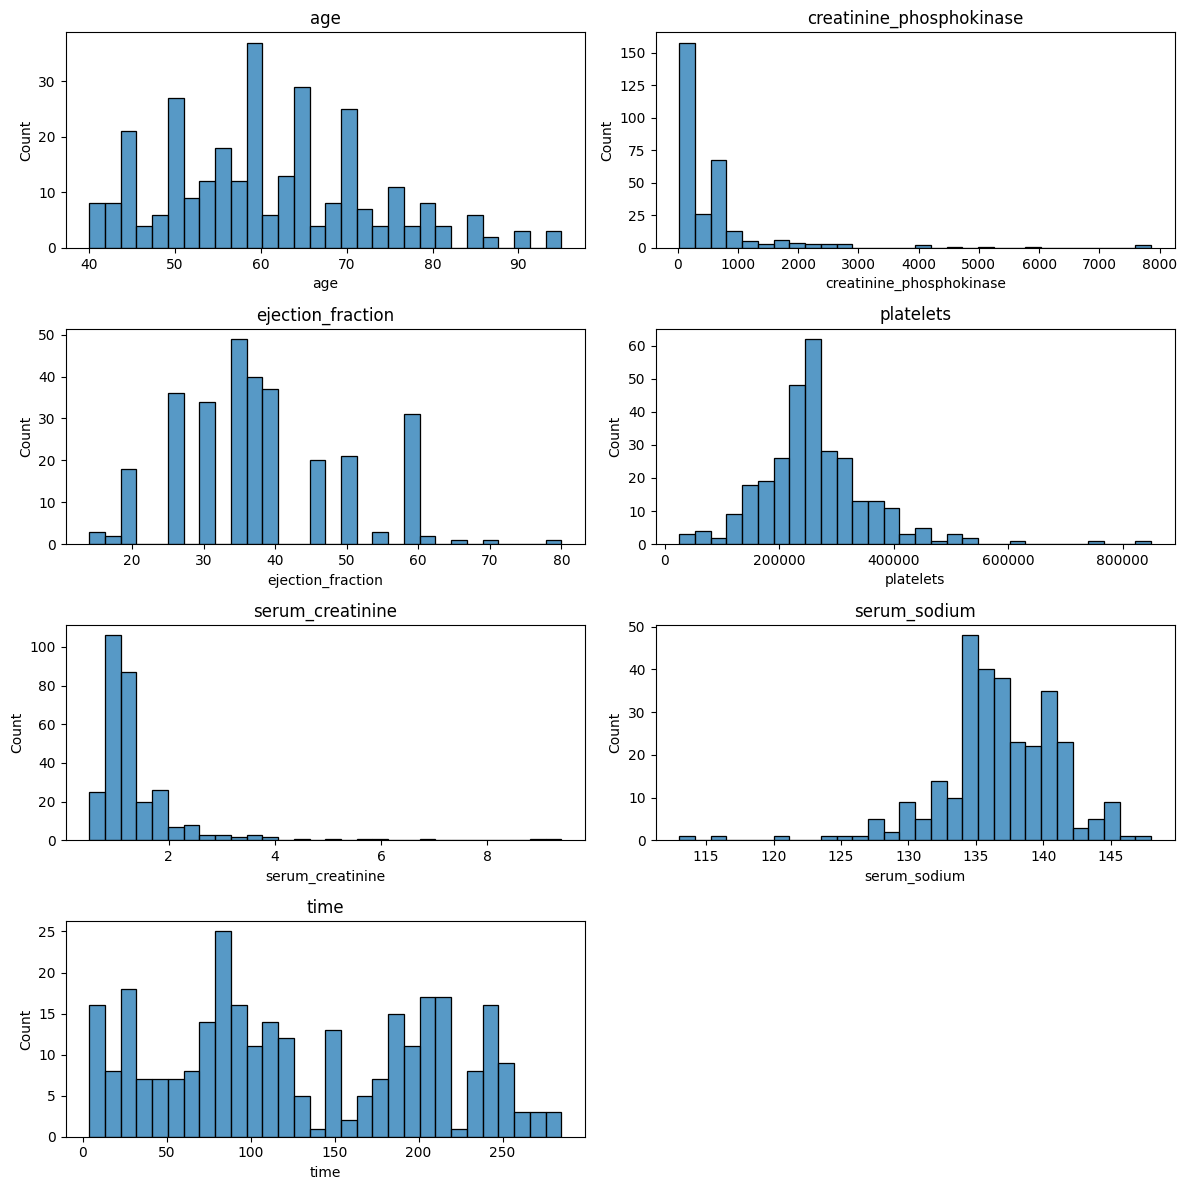

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65,1,160,1,20,0,327000.00,2.7,116,0,0,8,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
294,62,0,61,1,38,1,155000.00,1.1,143,1,1,270,0
295,55,0,1820,0,38,0,270000.00,1.2,139,0,0,271,0
296,45,0,2060,1,60,0,742000.00,0.8,138,0,0,278,0
297,45,0,2413,0,38,0,140000.00,1.4,140,1,1,280,0


In [42]:
# Check out the data set `heart_failure` and appropriately clean it.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data/heart_failure/heart_failure_clinical_records_dataset.csv')

# EDA
print(df.shape, "\n")
df.info()
display(df.head(n=15))
display(df.describe().T)
print("Missing values: ", df.isna().sum()[df.isna().sum() > 0])
print("Duplicate rows: ", df.duplicated().sum())

print("Potential non-int ages: ",df[df['age'] % 1 != 0])

# Histogram
numeric_cols = ['age', 'creatinine_phosphokinase', 'ejection_fraction',
            'platelets', 'serum_creatinine', 'serum_sodium', 'time']
fig, axes = plt.subplots(4, 2, figsize=(12, 12))
for ax, c in zip(axes.ravel(), numeric_cols):
    sns.histplot(x=df[c], ax=ax, bins=30)
    ax.set_title(c)
axes.ravel()[-1].axis('off')
plt.tight_layout()
plt.show()

# Small cleaning: floor the age column to convert it to int
df['age'] = np.floor(df['age']).astype(int)
df


We noticed that the distribution for many numeric columns like creatinine_phosphokinase, serum_creatinine, and platelets are skewed right, but we decided not to exclude data entries with extreme outliers because they may be medically possible. Further research and expert consulting would need to be done to determine if these values should be excluded. Additionally, we noticed that the age variable was stored as a float64 instead of an int64, so we explored the values and found 2 decimal ages. We floored these values to be consistent and converted the whole age column to integers.

### Question 2

In [43]:
# Perform a train-test split for a specific seed (save the seed for reproducibility).
import sklearn as sk
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score

seed1 = 42
X = df.drop('DEATH_EVENT', axis=1)
y = df['DEATH_EVENT']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed1)

# Fit a tree and a linear model on the training data and evaluate their performance on the test data.
tree = DecisionTreeClassifier(max_depth=3, random_state=seed1)
tree.fit(X_train, y_train)

linear = LinearRegression()
linear.fit(X_train, y_train)


# Set aside the predictions these models make.
prediction_tree_seed1 = tree.predict_proba(X_test)[:, 1]
prediction_linear_seed1 = linear.predict(X_test)

# Evaluation of both models
mse_tree = mean_squared_error(y_test, prediction_tree_seed1)
r2_tree = r2_score(y_test, prediction_tree_seed1)
print("Tree MSE:", mse_tree)
print("Tree R^2:", r2_tree)

mse_linear = mean_squared_error(y_test, prediction_linear_seed1)
r2_linear = r2_score(y_test, prediction_linear_seed1)
print("Linear MSE:", mse_linear)
print("Linear R^2:", r2_linear)

acc_tree = accuracy_score(y_test, prediction_tree_seed1 > 0.5)
acc_lin = accuracy_score(y_test, prediction_linear_seed1 > 0.5)
print("Tree accuracy:", acc_tree)
print("Linear accuracy:", acc_lin)

Tree MSE: 0.26359183539111136
Tree R^2: -0.08449212275200102
Linear MSE: 0.17867087264087422
Linear R^2: 0.26489698113468885
Tree accuracy: 0.6833333333333333
Linear accuracy: 0.8


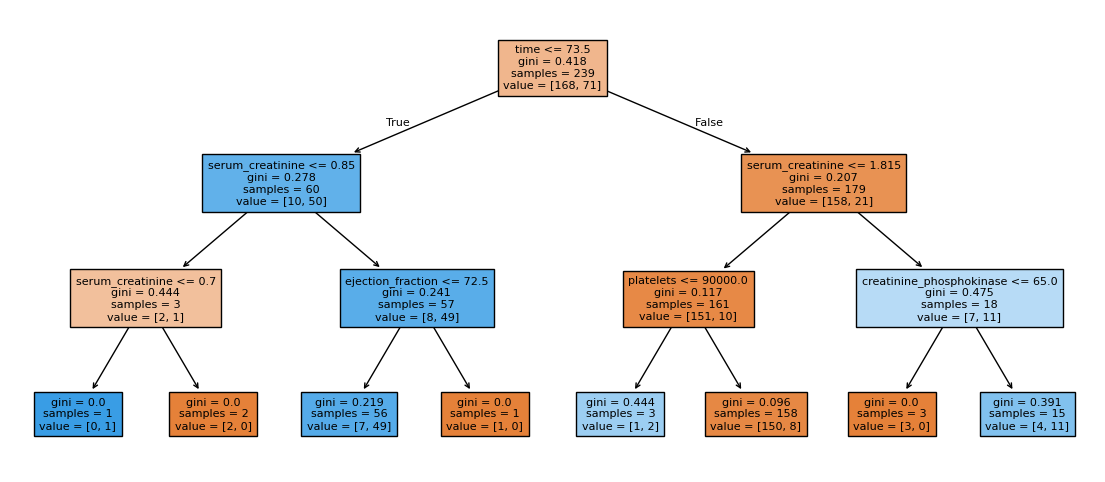

age                         0.006
anaemia                    -0.014
creatinine_phosphokinase    0.000
diabetes                    0.037
ejection_fraction          -0.009
high_blood_pressure        -0.022
platelets                  -0.000
serum_creatinine            0.107
serum_sodium               -0.006
sex                        -0.087
smoking                     0.017
time                       -0.003
dtype: float64


In [44]:
# Visual of decision tree and coefficients of linear model
from sklearn.tree import plot_tree

plt.figure(figsize=(14, 6))
plot_tree(tree, feature_names=X.columns, filled=True, fontsize=8)
plt.show()
print(pd.Series(linear.coef_, index=X.columns).round(3))

Using seed = 42, we saved the predictions that the tree and linear models made. We also evaluated the mean squared error, r-squared, and accuracy of both models. With an MSE of 0.18 versus 0.26, an r-squared of 0.26 versus -0.08, and an accuracy of 0.8 versus 0.68, the linear model outperformed the tree on all metrics, suggesting it is a better model.

We also visualized the decision flow of the tree. The tree splits first on time; patients followed 73.5 days or less mostly died (50/60 died), whereas patients followed longer had higher survival rates (158/179 survived). The tree then splits on serum_creatinine next for both sides. This makes sense because it is also the highest coefficient in the linear model.

### Question 3

Tree MSE: 0.10507545239572161
Tree R^2: 0.41262169468230137
Linear MSE: 0.12707510407530956
Linear R^2: 0.2896422753554122
Tree accuracy: 0.8666666666666667
Linear accuracy: 0.8833333333333333


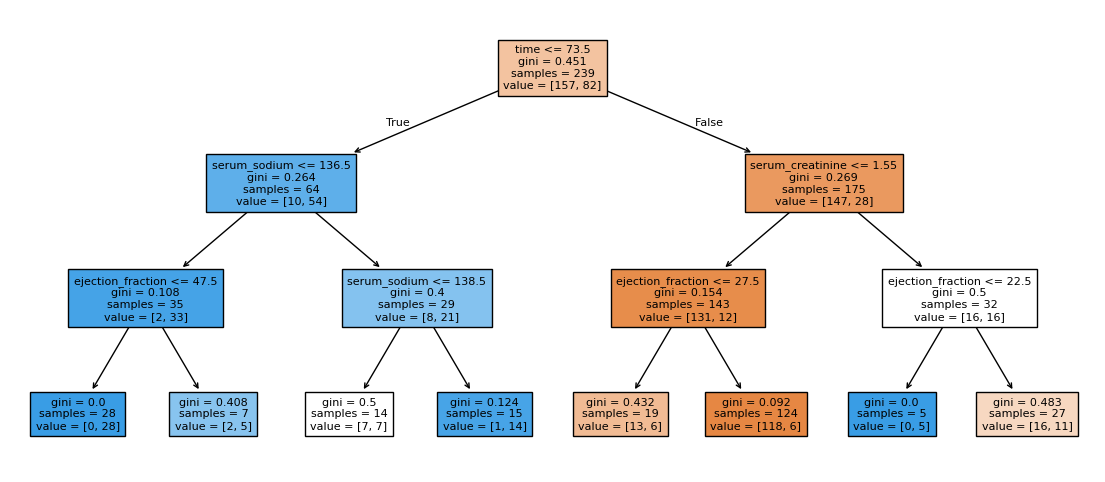

age                         0.005
anaemia                    -0.012
creatinine_phosphokinase    0.000
diabetes                    0.055
ejection_fraction          -0.010
high_blood_pressure        -0.042
platelets                  -0.000
serum_creatinine            0.091
serum_sodium               -0.008
sex                        -0.052
smoking                    -0.014
time                       -0.003
dtype: float64
Tree MSE: 0.09738569675900952
Tree R^2: 0.5203987574111705
Linear MSE: 0.11031386567951085
Linear R^2: 0.4567306204565812
Tree accuracy: 0.8833333333333333
Linear accuracy: 0.8666666666666667


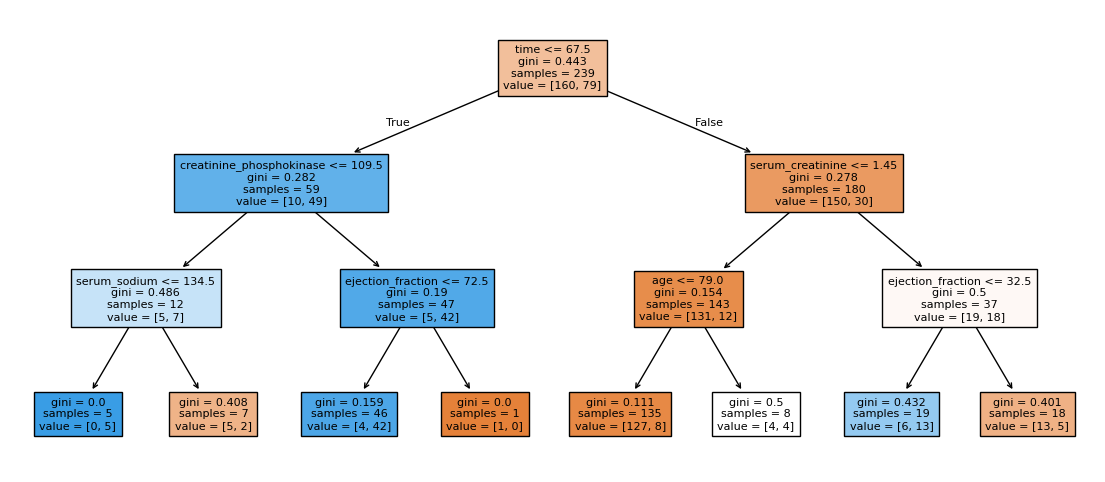

age                         0.006
anaemia                     0.006
creatinine_phosphokinase    0.000
diabetes                    0.007
ejection_fraction          -0.009
high_blood_pressure        -0.031
platelets                  -0.000
serum_creatinine            0.093
serum_sodium               -0.006
sex                        -0.075
smoking                    -0.013
time                       -0.003
dtype: float64
Tree MSE: 0.11915317694713265
Tree R^2: 0.4638107037379031
Linear MSE: 0.15099985004259767
Linear R^2: 0.3205006748083107
Tree accuracy: 0.8333333333333334
Linear accuracy: 0.8166666666666667


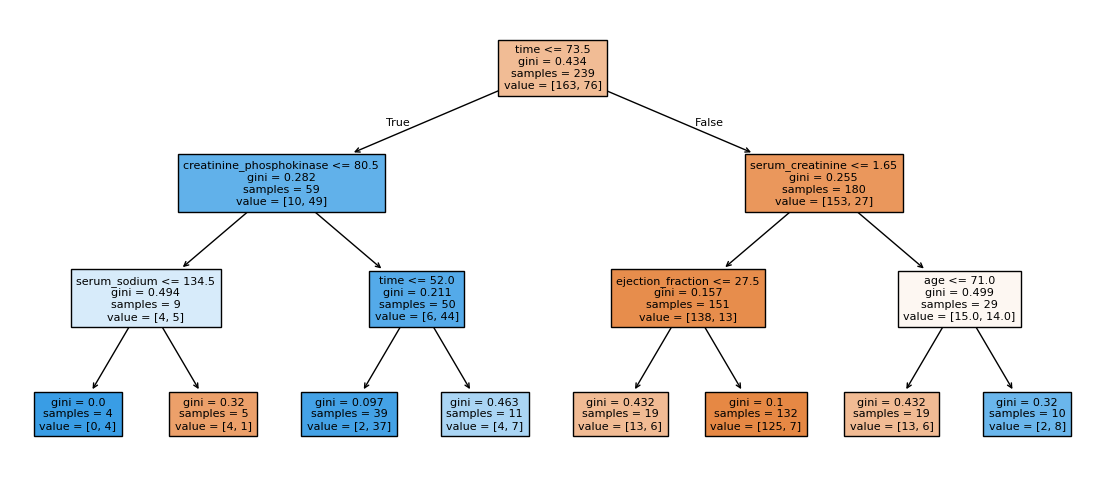

age                         0.007
anaemia                    -0.047
creatinine_phosphokinase    0.000
diabetes                    0.002
ejection_fraction          -0.011
high_blood_pressure        -0.044
platelets                  -0.000
serum_creatinine            0.072
serum_sodium               -0.008
sex                        -0.045
smoking                     0.023
time                       -0.003
dtype: float64


In [45]:
# Repeat step 2 for three to five different seeds (save the seeds for reproducibility). 
# How different are the trees that you get? Your linear model coefficients?. 
# Set aside the predictions these models make.



# ---------------- Seed 2 ----------------
seed2 = 1
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed2)

# Fit a tree and a linear model on the training data
tree2 = DecisionTreeClassifier(max_depth=3, random_state=seed2)
tree2.fit(X_train, y_train)

linear2 = LinearRegression()
linear2.fit(X_train, y_train)

# Set aside the predictions these models make
prediction_tree_seed2 = tree2.predict_proba(X_test)[:, 1]
prediction_linear_seed2 = linear2.predict(X_test)

# Evaluation of both models
mse_tree2 = mean_squared_error(y_test, prediction_tree_seed2)
r2_tree2 = r2_score(y_test, prediction_tree_seed2)
print("Tree MSE:", mse_tree2)
print("Tree R^2:", r2_tree2)

mse_linear2 = mean_squared_error(y_test, prediction_linear_seed2)
r2_linear2 = r2_score(y_test, prediction_linear_seed2)
print("Linear MSE:", mse_linear2)
print("Linear R^2:", r2_linear2)

acc_tree2 = accuracy_score(y_test, prediction_tree_seed2 > 0.5)
acc_lin2 = accuracy_score(y_test, prediction_linear_seed2 > 0.5)
print("Tree accuracy:", acc_tree2)
print("Linear accuracy:", acc_lin2)

# Visual of decision tree and coefficients of linear model
plt.figure(figsize=(14, 6))
plot_tree(tree2, feature_names=X.columns, filled=True, fontsize=8)
plt.show()
print(pd.Series(linear2.coef_, index=X.columns).round(3))

# ---------------- Seed 3 ----------------
seed3 = 2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed3)

# Fit a tree and a linear model on the training data
tree3 = DecisionTreeClassifier(max_depth=3, random_state=seed3)
tree3.fit(X_train, y_train)

linear3 = LinearRegression()
linear3.fit(X_train, y_train)

# Set aside the predictions these models make
prediction_tree_seed3 = tree3.predict_proba(X_test)[:, 1]
prediction_linear_seed3 = linear3.predict(X_test)

# Evaluation of both models
mse_tree3 = mean_squared_error(y_test, prediction_tree_seed3)
r2_tree3 = r2_score(y_test, prediction_tree_seed3)
print("Tree MSE:", mse_tree3)
print("Tree R^2:", r2_tree3)

mse_linear3 = mean_squared_error(y_test, prediction_linear_seed3)
r2_linear3 = r2_score(y_test, prediction_linear_seed3)
print("Linear MSE:", mse_linear3)
print("Linear R^2:", r2_linear3)

acc_tree3 = accuracy_score(y_test, prediction_tree_seed3 > 0.5)
acc_lin3 = accuracy_score(y_test, prediction_linear_seed3 > 0.5)
print("Tree accuracy:", acc_tree3)
print("Linear accuracy:", acc_lin3)

# Visual of decision tree and coefficients of linear model
plt.figure(figsize=(14, 6))
plot_tree(tree3, feature_names=X.columns, filled=True, fontsize=8)
plt.show()
print(pd.Series(linear3.coef_, index=X.columns).round(3))

# ---------------- Seed 4 ----------------
seed4 = 3
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed4)

# Fit a tree and a linear model on the training data
tree4 = DecisionTreeClassifier(max_depth=3, random_state=seed4)
tree4.fit(X_train, y_train)

linear4 = LinearRegression()
linear4.fit(X_train, y_train)

# Set aside the predictions these models make
prediction_tree_seed4 = tree4.predict_proba(X_test)[:, 1]
prediction_linear_seed4 = linear4.predict(X_test)

# Evaluation of both models
mse_tree4 = mean_squared_error(y_test, prediction_tree_seed4)
r2_tree4 = r2_score(y_test, prediction_tree_seed4)
print("Tree MSE:", mse_tree4)
print("Tree R^2:", r2_tree4)

mse_linear4 = mean_squared_error(y_test, prediction_linear_seed4)
r2_linear4 = r2_score(y_test, prediction_linear_seed4)
print("Linear MSE:", mse_linear4)
print("Linear R^2:", r2_linear4)

acc_tree4 = accuracy_score(y_test, prediction_tree_seed4 > 0.5)
acc_lin4 = accuracy_score(y_test, prediction_linear_seed4 > 0.5)
print("Tree accuracy:", acc_tree4)
print("Linear accuracy:", acc_lin4)

# Visual of decision tree and coefficients of linear model
plt.figure(figsize=(14, 6))
plot_tree(tree4, feature_names=X.columns, filled=True, fontsize=8)
plt.show()
print(pd.Series(linear4.coef_, index=X.columns).round(3))

In [46]:
# Comparing linear model coefficients across seeds
coef_table = pd.DataFrame({
    "seed 42": linear.coef_,
    "seed 1": linear2.coef_,
    "seed 2": linear3.coef_,
    "seed 3": linear4.coef_
}, index=X.columns)
display(coef_table.round(3))

# Comparing performance across seeds
results = pd.DataFrame({
    "seed": [42, 1, 2, 3],
    "tree MSE": [mse_tree, mse_tree2, mse_tree3, mse_tree4],
    "linear MSE": [mse_linear, mse_linear2, mse_linear3, mse_linear4],
    "tree R^2": [r2_tree, r2_tree2, r2_tree3, r2_tree4],
    "linear R^2": [r2_linear, r2_linear2, r2_linear3, r2_linear4],
    "tree accuracy": [acc_tree, acc_tree2, acc_tree3, acc_tree4],
    "linear accuracy": [acc_lin, acc_lin2, acc_lin3, acc_lin4]
})
display(results.round(3))

,seed 42,seed 1,seed 2,seed 3
age,0.006,0.005,0.006,0.007
anaemia,-0.014,-0.012,0.006,-0.047
creatinine_phosphokinase,0.000,0.000,0.000,0.000
diabetes,0.037,0.055,0.007,0.002
ejection_fraction,-0.009,-0.010,-0.009,-0.011
high_blood_pressure,-0.022,-0.042,-0.031,-0.044
platelets,-0.000,-0.000,-0.000,-0.000
serum_creatinine,0.107,0.091,0.093,0.072
serum_sodium,-0.006,-0.008,-0.006,-0.008
sex,-0.087,-0.052,-0.075,-0.045


,seed,tree MSE,linear MSE,tree R^2,linear R^2,tree accuracy,linear accuracy
0,42,0.264,0.179,-0.084,0.265,0.683,0.800
1,1,0.105,0.127,0.413,0.290,0.867,0.883
2,2,0.097,0.110,0.520,0.457,0.883,0.867
3,3,0.119,0.151,0.464,0.321,0.833,0.817


*Seed 1*: With seed = 1, the tree achieved an MSE of 0.11 versus 0.13 for the linear model, an R² of 0.41 versus 0.29, and an accuracy of 0.87 versus 0.88. The tree did better on MSE and R², while the linear model was slightly more accurate. The tree splits first on time (73.5 days or less mostly died, or 54/64 patients). On the short-follow-up side it then splits on serum_sodium and ejection_fraction, and on the long-follow-up side it splits on serum_creatinine and ejection_fraction.

*Seed 2*: With seed = 2, the tree achieved an MSE of 0.10 versus 0.11, an R² of 0.52 versus 0.46, and an accuracy of 0.88 versus 0.87. The tree performed slightly better on all three metrics. It splits first on time again, but at a different cutoff (67.5 days). The next splits are creatinine_phosphokinase and serum_creatinine, and a split on age appears lower down.

*Seed 3*: With seed = 3, the tree achieved an MSE of 0.12 versus 0.15, an R² of 0.46 versus 0.32, and an accuracy of 0.83 versus 0.82. The tree again outperformed the linear model on all metrics. It splits first on time (73.5), then on creatinine_phosphokinase and serum_creatinine, with further splits on time, ejection_fraction and age.

*Takeaways*: The time is always the tree root and first split, although the split point changes a couple of days between trees. Below this, the second-level split and beyond change a lot between trees. The trees look different seed-to-seed. The first tree, seed=42, might have been an unlucky pick becuase the linear model outperformed the tree in this instance, but the tree is a stronger model for all the other seeds (3/4 seeds, or 75% of the time).

### Question 4

By changing the seed, we change which patients the linear model will train on, and so some coefficients become more sensitive to being changed. For example, the time coefficient stays somewhere between -0.0028 and -0.0026, while the smoking coefficient changes sign across splits. The variables will also use different units, where the time coefficient is only for an additional day, while the smoking coefficient is for it changing from 0 to 1. These raw coefficient changes are difficult to compare among different features. 

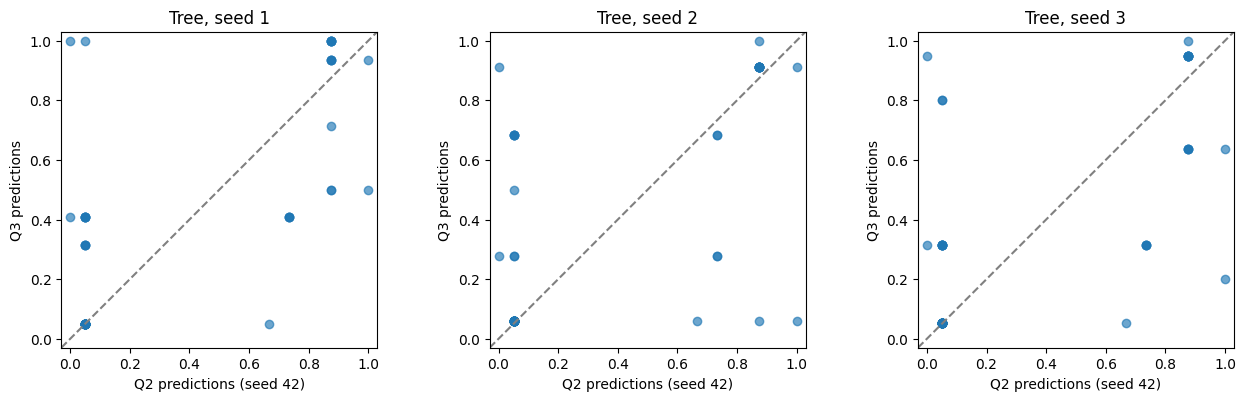

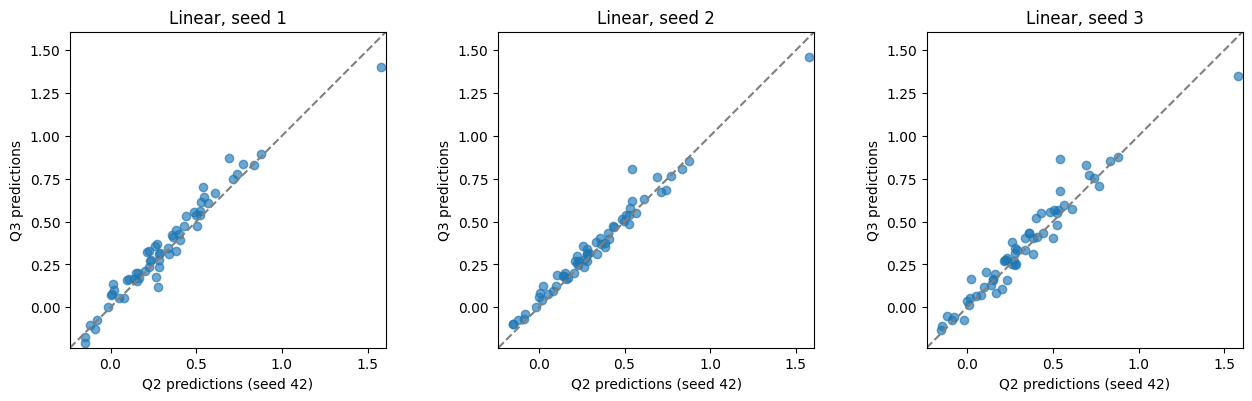

In [47]:
# Make scatterplots of the predicted values on the test set from question 2 against the predicted values 
# for the alternative models from part 3, separately for your trees and linear models.
_, X_test_q2, _, _ = train_test_split(X, y, test_size=0.2, random_state=seed1)

tree_predictions = [
    prediction_tree_seed1,
    tree2.predict_proba(X_test_q2)[:, 1],
    tree3.predict_proba(X_test_q2)[:, 1],
    tree4.predict_proba(X_test_q2)[:, 1]
]

linear_predictions = [
    prediction_linear_seed1,
    linear2.predict(X_test_q2),
    linear3.predict(X_test_q2),
    linear4.predict(X_test_q2)
]

alternative_seeds = [seed2, seed3, seed4]
model_groups = [("Tree", tree_predictions), ("Linear", linear_predictions)]

# Make scatterplots
for model_name, predictions in model_groups:
    q2_predictions = predictions[0]
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))

    low = min(pred.min() for pred in predictions) - 0.03
    high = max(pred.max() for pred in predictions) + 0.03

    for ax, seed, alternative in zip(axes, alternative_seeds, predictions[1:]):
        ax.scatter(q2_predictions, alternative, alpha=0.65)
        ax.plot([low, high], [low, high], "--", color="gray")
        ax.set_xlim(low, high)
        ax.set_ylim(low, high)
        ax.set_aspect("equal")
        ax.set_title(f"{model_name}, seed {seed}")
        ax.set_xlabel(f"Q2 predictions (seed {seed1})")
        ax.set_ylabel("Q3 predictions")

    plt.tight_layout()
    plt.show()

Here, we see that the linear predictions do look reasonably similar, since most of the points are close to the dashed line where the two predictions would be equal. When we look at the trees, we see that they agree for some patients, but many points do end up far away from the line. There is also a lot of clustering for the tree points, since patients in the same leaf get the same predicted probability. All these comparisons use the same test patients from question 2, some of who were also in question 3's training sets, so there is some agreement in the plots with those patients. 

In [48]:
# Compute the correlation between your model in part 2 and your alternative models in part 3, 
# separately for your trees and linear models.
correlation_results = []

for model_name, predictions in model_groups:
    q2_predictions = predictions[0]

    for seed, alternative in zip(alternative_seeds, predictions[1:]):
        correlation = np.corrcoef(q2_predictions, alternative)[0, 1]

        correlation_results.append({
            "Model": model_name,
            "Q3 seed": seed,
            "Correlation": correlation
        })

display(pd.DataFrame(correlation_results).round(3))

,Model,Q3 seed,Correlation
0,Tree,1,0.733
1,Tree,2,0.675
2,Tree,3,0.699
3,Linear,1,0.978
4,Linear,2,0.987
5,Linear,3,0.967


The linear predictions are highly correlated with the predictions from question truth, with correlations ranging from 0.967 to 0.987. The tree predictions, on the other hand, have weaker correlations, from 0.675 to 0.733, across all the different seeds. The tree predictions tend to move in the same direction, but they have a much less consistent relationship than the linear models do. 

In [49]:
# Run a simple linear regression of the predicted values on the test set from the alternative models on the 
# predicted values from question 2, separately for your trees and linear models.

regression_results = []

for model_name, predictions in model_groups:
    # Use Q2 predictions as X and the alternative model's predictions as Y
    q2_predictions = predictions[0].reshape(-1, 1)

    for seed, alternative in zip(alternative_seeds, predictions[1:]):
        comparison = LinearRegression()
        comparison.fit(q2_predictions, alternative)

        regression_results.append({
            "Model": model_name,
            "Q3 seed": seed,
            "Intercept": comparison.intercept_,
            "Slope": comparison.coef_[0],
            "R²": comparison.score(q2_predictions, alternative)
        })

display(pd.DataFrame(regression_results).round(3))

,Model,Q3 seed,Intercept,Slope,R²
0,Tree,1,0.147,0.697,0.538
1,Tree,2,0.153,0.654,0.455
2,Tree,3,0.138,0.630,0.489
3,Linear,1,0.033,0.984,0.956
4,Linear,2,0.048,0.931,0.974
5,Linear,3,0.040,0.952,0.935


For the linear models, we see that the intercepts range from around 0.033 to 0.048, staying fairly close to zero, with slopes ranging from 0.931 to 0.984, staying close to one, and R-squared values that range from 0.935 to 0.974, also staying close to one. This is consistent with the points that follow the dashed line in Q4a.

When we look at the trees, the intercepts range from 0.138 to 0.153, being farther from zero than the linear models, with slopes ranging from 0.630 to 0.697, being significantly farther from one. R-squared values range from 0.445 to 0.538, which are much lower than the linear models. Overall, it can be concluded that the linear models give much more similar predictions across the training splits. 

### Question 5

*Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?*

Linear models appear to be stable across train/test splits and their key coefficients like age, ejection fraction, serum creatinine, etc don’t have that much change between seeds and their predictions are roughly identical with an average correlation of about 0.98 across all rows. The trees on the other hand are not stable and the split cutoffs, lower branches, and number of leaves change from seed to seed but their predictions agree only a few times with an average/moderate correlation of about 0.72.

### Question 6

*True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."*

This is true regarding this dataset, however, the linear models look alike and give about the same predictions with the correlations being from 0.967 to 0.987, slopes are close to 1, and R^2 is between 0.935 and 0.974. The trees look different from one another but their predictions are still positively correlated (0.675-0.733), because they all mainly split on age, serum creatinine, ejection fraction, and sodium. The agreement for trees is only moderate, so “very similar” describes the linear models well but overstates how closely the trees agree.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 9def7e991cb7873cece8eb897813c17377bf055d
- **AI tool and model used:** Claude Sonnet 5.5

### *Prompts used

1. "Attached is the rubric and notebook. Compare our work with the rubric and suggest improvements for phase 2" (attached notebook and rubric)
2. "Focus on essential changes only (not "nice-to-haves) and give them in list format by question order"

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Q1:
Drop time after your exploration: df = df.drop(columns='time'). Explain that it is the follow-up period, so it isn’t known at baseline. It also leaks the outcome, because patients who died were followed for 71 days on average versus 158 for survivors (correlation about -0.53).
Add one sentence noting that 25 platelet values equal the column mean (263358.03), likely from earlier imputation. State whether you kept them or imputed them, since the current text doesn’t mention this.
2. Q2:
Re-run and update the numbers. For seed 42 the tree has an MSE of 0.219, R² of 0.10 and accuracy of 0.73. The linear model has an MSE of 0.227, R² of 0.07 and accuracy of 0.67.
Remove the claim that the linear model is better. The two are about equal, and both are weak.
Rewrite the tree description: it now splits first on serum_creatinine, then ejection_fraction, with age at the third level.
3. Q3:
Re-run and rewrite all three seed explanations plus the takeaways.
Neither model wins consistently. The tree has the lower MSE in 3 of 4 seeds by tiny margins, and accuracy is mixed (tree 0.73 to 0.77, linear 0.67 to 0.82). R² is low for both (0.07 to 0.23).
The trees now look more alike. Every tree splits first on serum_creatinine (cutoff 1.45 to 1.81), second on ejection_fraction (27.5 to 32.5), and third on age (about 79). Only the remaining splits vary: serum_sodium in two trees and serum_creatinine again in two.
Linear coefficients are stable for serum_creatinine (0.109 to 0.128), ejection_fraction (about -0.010) and age (0.008 to 0.010). diabetes changes sign.
Make the seed labels consistent. The code comments say “Seed 2/3/4” for seeds 1, 2 and 3, while the markdown says “Seed 1/2/3.”
4. Q4:
4.1: The current text uses time and smoking as examples, and neither applies anymore. Use diabetes (0.029, 0.058, -0.012, -0.007) as the sign-change example. For comparison, serum_creatinine and ejection_fraction barely move. Also show the unrounded range or std per coefficient, since rounding to 3 decimals hides the CPK and platelets coefficients.
4a to 4c: Re-run and update all the numbers. Tree correlations are 0.57, 0.58 and 0.77, and linear are 0.96 to 0.98. For the regressions, tree intercepts are 0.10 to 0.18, slopes 0.56 to 0.78 and R² 0.32 to 0.59, while linear intercepts are 0.05 to 0.06, slopes 0.90 to 0.93 and R² 0.93 to 0.96. Keep your caveat about the Q2 test patients overlapping the alternative models’ training sets.
Fix the typo “question truth,” which should be “question 2.”
5. Q5:
Update the averages. Trees are about 0.64 (not 0.72, which was also wrong with time included, where it was 0.70). Linear is about 0.98.
Say the linear predictions are “very similar” rather than “roughly identical.”
Name the one unstable linear coefficient, diabetes.
6. Q6:
Start with one clear verdict. Your current answer says “True” and then says the claim overstates the trees.
With time removed, the trees’ structures are fairly similar, but their predictions agree only moderately (correlation 0.57 to 0.77). They give the same death/survive call for 70 to 88% of patients, versus 93 to 95% for linear. My reading is “true for the linear models, not for the trees.” That is your call, so choose the verdict your final numbers support.
Your sentence about the shared splits (age, serum_creatinine, ejection_fraction, sodium) now matches the trees. Add that serum_creatinine and ejection_fraction are at the top of every tree.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Modify | Drop time because it creates a leakage issue, but keep platelet values as is because there's no way to prove if they're supposed to be the mean or not |
| 2 | Accept | Results change due to dropping time variable |
| 3 | Accept | Results change due to dropping time variable |
| 4 | Accept | Results change due to dropping time variable |
| 5 | Accept | Results change due to dropping time |
| 6 | Accept | Results change due to dropping time |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

### Question 1

(299, 13) 

<class 'pandas.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1
5,90.0,1,47,0,40,1,204000.00,2.1,132,1,1,8,1
6,75.0,1,246,0,15,0,127000.00,1.2,137,1,0,10,1
7,60.0,1,315,1,60,0,454000.00,1.1,131,1,1,10,1
8,65.0,0,157,0,65,0,263358.03,1.5,138,0,0,10,1
9,80.0,1,123,0,35,1,388000.00,9.4,133,1,1,10,1


,count,mean,std,min,25%,50%,75%,max
age,299.0,60.833893,11.894809,40.0,51.0,60.0,70.0,95.0
anaemia,299.0,0.431438,0.496107,0.0,0.0,0.0,1.0,1.0
creatinine_phosphokinase,299.0,581.839465,970.287881,23.0,116.5,250.0,582.0,7861.0
diabetes,299.0,0.418060,0.494067,0.0,0.0,0.0,1.0,1.0
ejection_fraction,299.0,38.083612,11.834841,14.0,30.0,38.0,45.0,80.0
high_blood_pressure,299.0,0.351171,0.478136,0.0,0.0,0.0,1.0,1.0
platelets,299.0,263358.029264,97804.236869,25100.0,212500.0,262000.0,303500.0,850000.0
serum_creatinine,299.0,1.393880,1.034510,0.5,0.9,1.1,1.4,9.4
serum_sodium,299.0,136.625418,4.412477,113.0,134.0,137.0,140.0,148.0
sex,299.0,0.648829,0.478136,0.0,0.0,1.0,1.0,1.0


Missing values:  Series([], dtype: int64)
Duplicate rows:  0
Potential non-int ages:          age  anaemia  creatinine_phosphokinase  diabetes  ejection_fraction  \
185  60.667        1                       104         1                 30   
188  60.667        1                       151         1                 40   

     high_blood_pressure  platelets  serum_creatinine  serum_sodium  sex  \
185                    0   389000.0               1.5           136    1   
188                    1   201000.0               1.0           136    0   

     smoking  time  DEATH_EVENT  
185        0   171            1  
188        0   172            0  


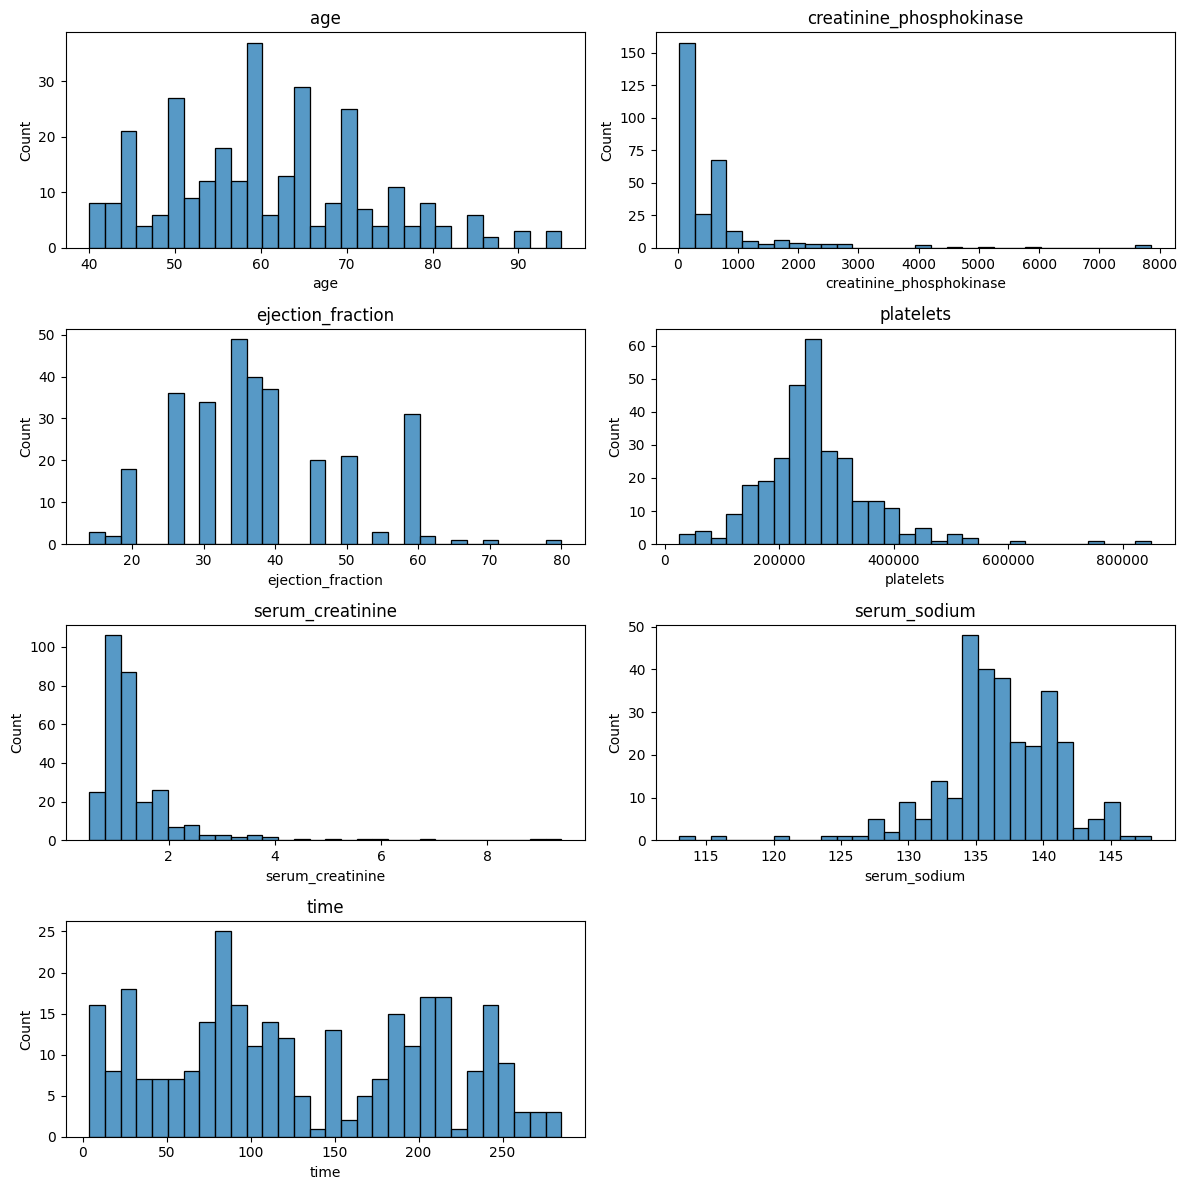

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,DEATH_EVENT
0,75,0,582,0,20,1,265000.00,1.9,130,1,0,1
1,55,0,7861,0,38,0,263358.03,1.1,136,1,0,1
2,65,0,146,0,20,0,162000.00,1.3,129,1,1,1
3,50,1,111,0,20,0,210000.00,1.9,137,1,0,1
4,65,1,160,1,20,0,327000.00,2.7,116,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
294,62,0,61,1,38,1,155000.00,1.1,143,1,1,0
295,55,0,1820,0,38,0,270000.00,1.2,139,0,0,0
296,45,0,2060,1,60,0,742000.00,0.8,138,0,0,0
297,45,0,2413,0,38,0,140000.00,1.4,140,1,1,0


In [50]:
# Check out the data set `heart_failure` and appropriately clean it.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data/heart_failure/heart_failure_clinical_records_dataset.csv')

# EDA
print(df.shape, "\n")
df.info()
display(df.head(n=15))
display(df.describe().T)
print("Missing values: ", df.isna().sum()[df.isna().sum() > 0])
print("Duplicate rows: ", df.duplicated().sum())

print("Potential non-int ages: ",df[df['age'] % 1 != 0])

# Histogram
numeric_cols = ['age', 'creatinine_phosphokinase', 'ejection_fraction',
            'platelets', 'serum_creatinine', 'serum_sodium', 'time']
fig, axes = plt.subplots(4, 2, figsize=(12, 12))
for ax, c in zip(axes.ravel(), numeric_cols):
    sns.histplot(x=df[c], ax=ax, bins=30)
    ax.set_title(c)
axes.ravel()[-1].axis('off')
plt.tight_layout()
plt.show()

# Small cleaning: floor the age column to convert it to int, drop leakage time
df['age'] = np.floor(df['age']).astype(int)
df = df.drop(columns='time')
df


We noticed that the distribution for many numeric columns like creatinine_phosphokinase, serum_creatinine, and platelets are skewed right, but we decided not to exclude data entries with extreme outliers because they may be medically possible. Further research and expert consulting would need to be done to determine if these values should be excluded. Additionally, we noticed that the age variable was stored as a float64 instead of an int64, so we explored the values and found 2 decimal ages. We floored these values to be consistent and converted the whole age column to integers. Lastly, we dropped the time variable because it correlates with the target variable DEATH_EVENT, since once a patient dies, they cannot be evaluated further and time variable "stops."

### Question 2

In [51]:
# Perform a train-test split for a specific seed (save the seed for reproducibility).
import sklearn as sk
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score

seed1 = 42
X = df.drop('DEATH_EVENT', axis=1)
y = df['DEATH_EVENT']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed1)

# Fit a tree and a linear model on the training data and evaluate their performance on the test data.
tree = DecisionTreeClassifier(max_depth=3, random_state=seed1)
tree.fit(X_train, y_train)

linear = LinearRegression()
linear.fit(X_train, y_train)


# Set aside the predictions these models make.
prediction_tree_seed1 = tree.predict_proba(X_test)[:, 1]
prediction_linear_seed1 = linear.predict(X_test)

# Evaluation of both models
mse_tree = mean_squared_error(y_test, prediction_tree_seed1)
r2_tree = r2_score(y_test, prediction_tree_seed1)
print("Tree MSE:", mse_tree)
print("Tree R^2:", r2_tree)

mse_linear = mean_squared_error(y_test, prediction_linear_seed1)
r2_linear = r2_score(y_test, prediction_linear_seed1)
print("Linear MSE:", mse_linear)
print("Linear R^2:", r2_linear)

acc_tree = accuracy_score(y_test, prediction_tree_seed1 > 0.5)
acc_lin = accuracy_score(y_test, prediction_linear_seed1 > 0.5)
print("Tree accuracy:", acc_tree)
print("Linear accuracy:", acc_lin)

Tree MSE: 0.21945037654607877
Tree R^2: 0.09711845078184733
Linear MSE: 0.2273129931616849
Linear R^2: 0.06476939956335348
Tree accuracy: 0.7333333333333333
Linear accuracy: 0.6666666666666666


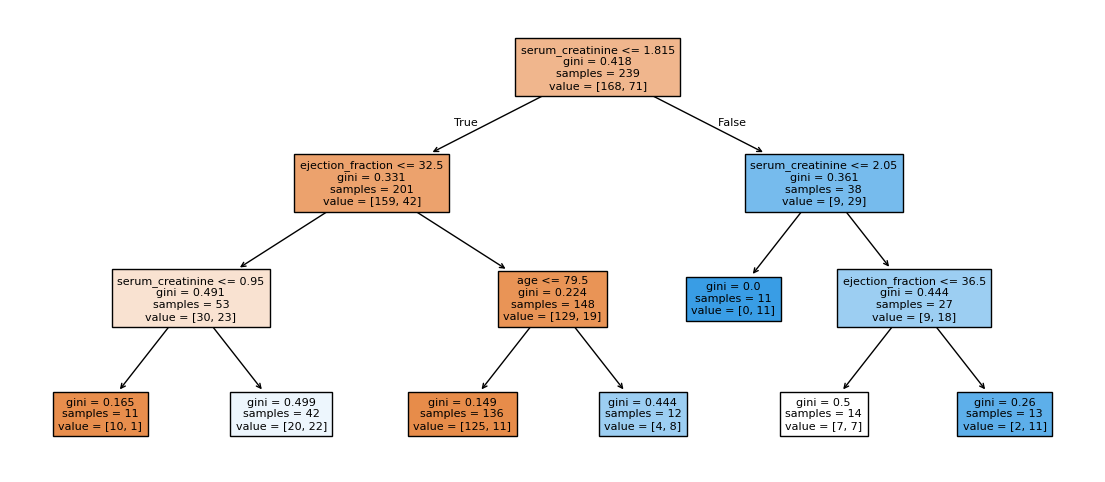

age                         0.010
anaemia                     0.041
creatinine_phosphokinase    0.000
diabetes                    0.029
ejection_fraction          -0.010
high_blood_pressure         0.070
platelets                  -0.000
serum_creatinine            0.128
serum_sodium               -0.008
sex                        -0.096
smoking                     0.025
dtype: float64


In [52]:
# Visual of decision tree and coefficients of linear model
from sklearn.tree import plot_tree

plt.figure(figsize=(14, 6))
plot_tree(tree, feature_names=X.columns, filled=True, fontsize=8)
plt.show()
print(pd.Series(linear.coef_, index=X.columns).round(3))

Using seed = 42, we saved the predictions that the tree and linear models made. With an MSE of 0.219 versus 0.227, an r-squared of 0.097 versus 0.065, and an accuracy of 0.733 versus 0.667, the tree performed slightly better than the linear model on all metrics, but the difference is small and both models explain very little of the variation in the outcome.

We also visualized the decision flow of the tree. The tree splits first on serum_creatinine; patients with a level above 1.81 mostly died (29/38 died), whereas patients at or below 1.81 mostly survived (159/201 survived). For the lower serum creatinine patients, the tree then splits on ejection_fraction, where those with an ejection fraction of 32.5 or lower died more often (23/53) than those with a higher one (19/148). For the higher serum creatinine patients, it splits on serum_creatinine again (2.05). This makes sense because serum_creatinine also has the largest coefficient in the linear model (0.128), and ejection_fraction has a negative coefficient (-0.010).

### Question 3

Tree MSE: 0.14736991755559284
Tree R^2: 0.17619300745320743
Linear MSE: 0.15046624131270542
Linear R^2: 0.15888436533270245
Tree accuracy: 0.7666666666666667
Linear accuracy: 0.8


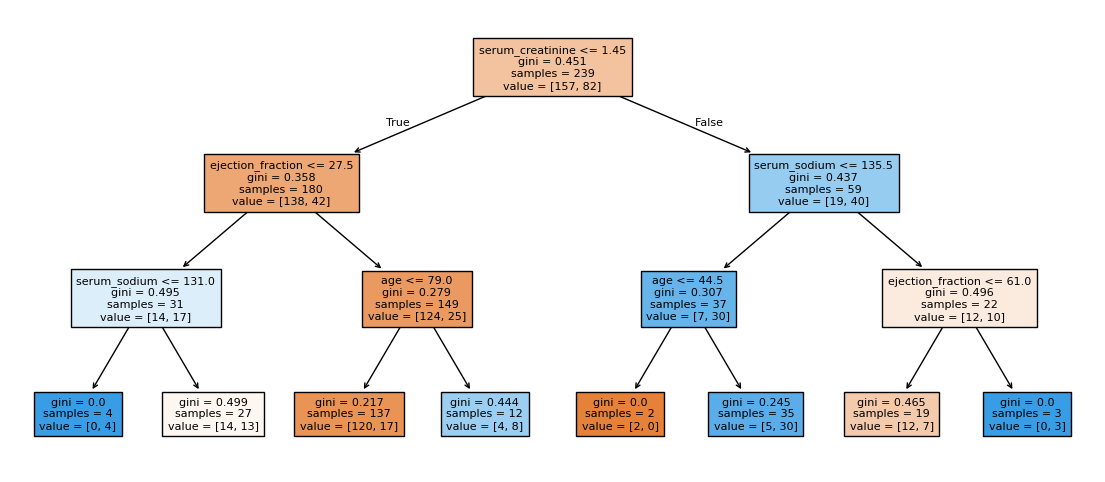

age                         0.008
anaemia                     0.054
creatinine_phosphokinase    0.000
diabetes                    0.058
ejection_fraction          -0.010
high_blood_pressure         0.037
platelets                  -0.000
serum_creatinine            0.115
serum_sodium               -0.012
sex                        -0.060
smoking                     0.005
dtype: float64
Tree MSE: 0.17000451534362307
Tree R^2: 0.1627684606880393
Linear MSE: 0.1639407488117304
Linear R^2: 0.1926310592035163
Tree accuracy: 0.75
Linear accuracy: 0.8166666666666667


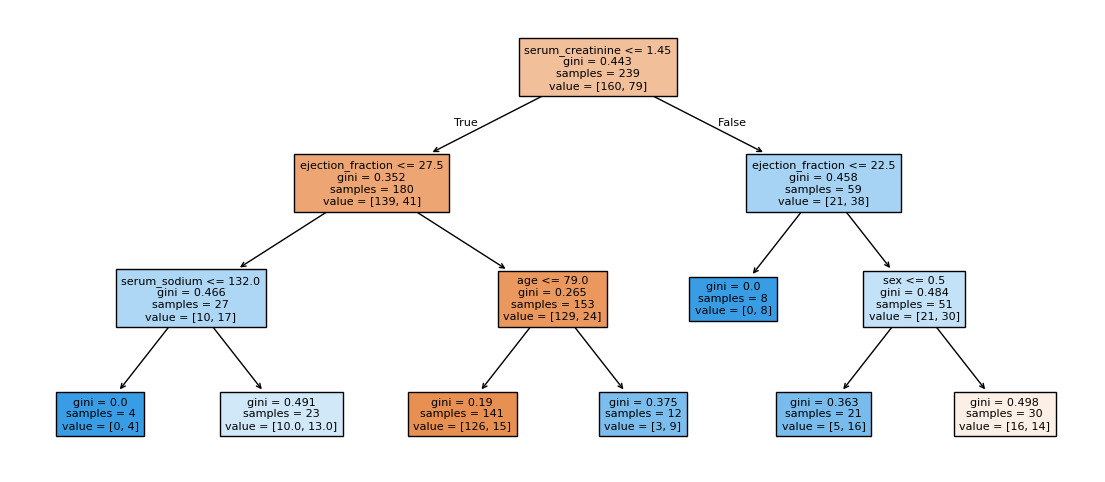

age                         0.009
anaemia                     0.063
creatinine_phosphokinase    0.000
diabetes                   -0.012
ejection_fraction          -0.010
high_blood_pressure         0.045
platelets                  -0.000
serum_creatinine            0.111
serum_sodium               -0.010
sex                        -0.080
smoking                     0.002
dtype: float64
Tree MSE: 0.17020058421231404
Tree R^2: 0.23409737104458694
Linear MSE: 0.1942634880809579
Linear R^2: 0.12581430363568957
Tree accuracy: 0.7666666666666667
Linear accuracy: 0.6666666666666666


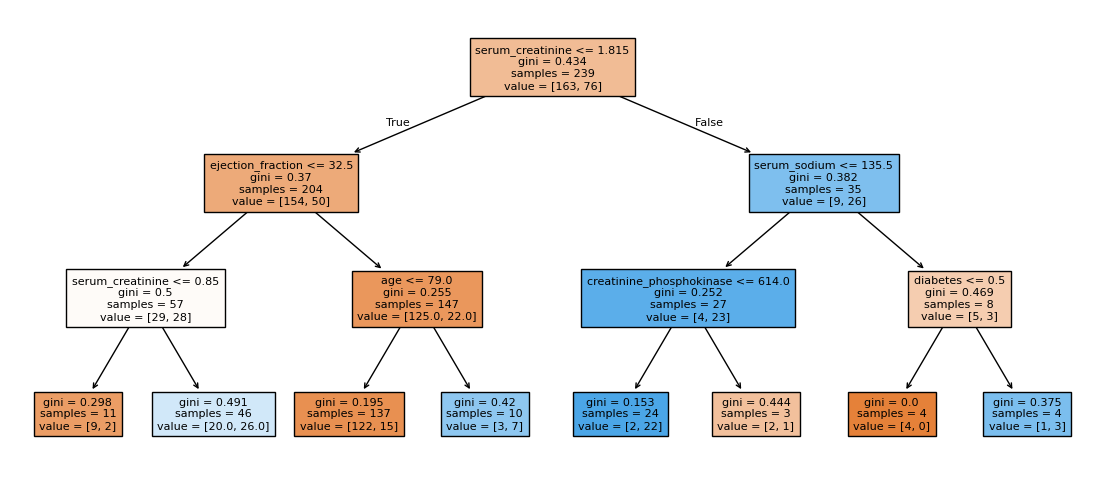

age                         0.010
anaemia                     0.004
creatinine_phosphokinase    0.000
diabetes                   -0.006
ejection_fraction          -0.010
high_blood_pressure         0.068
platelets                  -0.000
serum_creatinine            0.109
serum_sodium               -0.013
sex                        -0.060
smoking                     0.029
dtype: float64


In [53]:
# Repeat step 2 for three to five different seeds (save the seeds for reproducibility). 
# How different are the trees that you get? Your linear model coefficients?. 
# Set aside the predictions these models make.



# ---------------- Seed 2 ----------------
seed2 = 1
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed2)

# Fit a tree and a linear model on the training data
tree2 = DecisionTreeClassifier(max_depth=3, random_state=seed2)
tree2.fit(X_train, y_train)

linear2 = LinearRegression()
linear2.fit(X_train, y_train)

# Set aside the predictions these models make
prediction_tree_seed2 = tree2.predict_proba(X_test)[:, 1]
prediction_linear_seed2 = linear2.predict(X_test)

# Evaluation of both models
mse_tree2 = mean_squared_error(y_test, prediction_tree_seed2)
r2_tree2 = r2_score(y_test, prediction_tree_seed2)
print("Tree MSE:", mse_tree2)
print("Tree R^2:", r2_tree2)

mse_linear2 = mean_squared_error(y_test, prediction_linear_seed2)
r2_linear2 = r2_score(y_test, prediction_linear_seed2)
print("Linear MSE:", mse_linear2)
print("Linear R^2:", r2_linear2)

acc_tree2 = accuracy_score(y_test, prediction_tree_seed2 > 0.5)
acc_lin2 = accuracy_score(y_test, prediction_linear_seed2 > 0.5)
print("Tree accuracy:", acc_tree2)
print("Linear accuracy:", acc_lin2)

# Visual of decision tree and coefficients of linear model
plt.figure(figsize=(14, 6))
plot_tree(tree2, feature_names=X.columns, filled=True, fontsize=8)
plt.show()
print(pd.Series(linear2.coef_, index=X.columns).round(3))

# ---------------- Seed 3 ----------------
seed3 = 2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed3)

# Fit a tree and a linear model on the training data
tree3 = DecisionTreeClassifier(max_depth=3, random_state=seed3)
tree3.fit(X_train, y_train)

linear3 = LinearRegression()
linear3.fit(X_train, y_train)

# Set aside the predictions these models make
prediction_tree_seed3 = tree3.predict_proba(X_test)[:, 1]
prediction_linear_seed3 = linear3.predict(X_test)

# Evaluation of both models
mse_tree3 = mean_squared_error(y_test, prediction_tree_seed3)
r2_tree3 = r2_score(y_test, prediction_tree_seed3)
print("Tree MSE:", mse_tree3)
print("Tree R^2:", r2_tree3)

mse_linear3 = mean_squared_error(y_test, prediction_linear_seed3)
r2_linear3 = r2_score(y_test, prediction_linear_seed3)
print("Linear MSE:", mse_linear3)
print("Linear R^2:", r2_linear3)

acc_tree3 = accuracy_score(y_test, prediction_tree_seed3 > 0.5)
acc_lin3 = accuracy_score(y_test, prediction_linear_seed3 > 0.5)
print("Tree accuracy:", acc_tree3)
print("Linear accuracy:", acc_lin3)

# Visual of decision tree and coefficients of linear model
plt.figure(figsize=(14, 6))
plot_tree(tree3, feature_names=X.columns, filled=True, fontsize=8)
plt.show()
print(pd.Series(linear3.coef_, index=X.columns).round(3))

# ---------------- Seed 4 ----------------
seed4 = 3
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed4)

# Fit a tree and a linear model on the training data
tree4 = DecisionTreeClassifier(max_depth=3, random_state=seed4)
tree4.fit(X_train, y_train)

linear4 = LinearRegression()
linear4.fit(X_train, y_train)

# Set aside the predictions these models make
prediction_tree_seed4 = tree4.predict_proba(X_test)[:, 1]
prediction_linear_seed4 = linear4.predict(X_test)

# Evaluation of both models
mse_tree4 = mean_squared_error(y_test, prediction_tree_seed4)
r2_tree4 = r2_score(y_test, prediction_tree_seed4)
print("Tree MSE:", mse_tree4)
print("Tree R^2:", r2_tree4)

mse_linear4 = mean_squared_error(y_test, prediction_linear_seed4)
r2_linear4 = r2_score(y_test, prediction_linear_seed4)
print("Linear MSE:", mse_linear4)
print("Linear R^2:", r2_linear4)

acc_tree4 = accuracy_score(y_test, prediction_tree_seed4 > 0.5)
acc_lin4 = accuracy_score(y_test, prediction_linear_seed4 > 0.5)
print("Tree accuracy:", acc_tree4)
print("Linear accuracy:", acc_lin4)

# Visual of decision tree and coefficients of linear model
plt.figure(figsize=(14, 6))
plot_tree(tree4, feature_names=X.columns, filled=True, fontsize=8)
plt.show()
print(pd.Series(linear4.coef_, index=X.columns).round(3))

In [54]:
# Comparing linear model coefficients across seeds
coef_table = pd.DataFrame({
    "seed 42": linear.coef_,
    "seed 1": linear2.coef_,
    "seed 2": linear3.coef_,
    "seed 3": linear4.coef_
}, index=X.columns)
display(coef_table.round(3))

# Comparing performance across seeds
results = pd.DataFrame({
    "seed": [42, 1, 2, 3],
    "tree MSE": [mse_tree, mse_tree2, mse_tree3, mse_tree4],
    "linear MSE": [mse_linear, mse_linear2, mse_linear3, mse_linear4],
    "tree R^2": [r2_tree, r2_tree2, r2_tree3, r2_tree4],
    "linear R^2": [r2_linear, r2_linear2, r2_linear3, r2_linear4],
    "tree accuracy": [acc_tree, acc_tree2, acc_tree3, acc_tree4],
    "linear accuracy": [acc_lin, acc_lin2, acc_lin3, acc_lin4]
})
display(results.round(3))

,seed 42,seed 1,seed 2,seed 3
age,0.010,0.008,0.009,0.010
anaemia,0.041,0.054,0.063,0.004
creatinine_phosphokinase,0.000,0.000,0.000,0.000
diabetes,0.029,0.058,-0.012,-0.006
ejection_fraction,-0.010,-0.010,-0.010,-0.010
high_blood_pressure,0.070,0.037,0.045,0.068
platelets,-0.000,-0.000,-0.000,-0.000
serum_creatinine,0.128,0.115,0.111,0.109
serum_sodium,-0.008,-0.012,-0.010,-0.013
sex,-0.096,-0.060,-0.080,-0.060


,seed,tree MSE,linear MSE,tree R^2,linear R^2,tree accuracy,linear accuracy
0,42,0.219,0.227,0.097,0.065,0.733,0.667
1,1,0.147,0.150,0.176,0.159,0.767,0.800
2,2,0.170,0.164,0.163,0.193,0.750,0.817
3,3,0.170,0.194,0.234,0.126,0.767,0.667


Seed 1: With seed = 1, the tree achieved an MSE of 0.147 versus 0.150 for the linear model, an R² of 0.18 versus 0.16, and an accuracy of 0.77 versus 0.80. The tree was slightly better on MSE and R², while the linear model was more accurate. The tree splits first on serum_creatinine (1.45; patients above this mostly died, or 40/59 patients). On the lower side it then splits on ejection_fraction (27.5), and on the higher side it splits on serum_sodium (135.5), with age and more splits further down.

Seed 2: With seed = 2, the tree achieved an MSE of 0.17 versus 0.16, an R² of 0.16 versus 0.19, and an accuracy of 0.75 versus 0.82. The linear model performed better on all three metrics. The tree splits first on serum_creatinine again at the same cutoff (1.45). The next splits are ejection_fraction (27.5) on the lower side and ejection_fraction (22.5) on the higher side, followed by splits on serum_sodium, age, and sex.

Seed 3: With seed = 3, the tree achieved an MSE of 0.17 versus 0.19, an R² of 0.23 versus 0.13, and an accuracy of 0.77 versus 0.67. The tree outperformed the linear model on all metrics. It splits first on serum_creatinine (1.81), then on ejection_fraction (32.5) on the lower side, followed by serum_creatinine and age. On the higher side it splits on serum_sodium, then on creatinine_phosphokinase and diabetes.

Takeaways: serum_creatinine is always the tree root, with the cutoff at either 1.45 or 1.81 (seeds 42 and 3 share 1.81 and 32.5, and seeds 1 and 2 share 1.45 and 27.5). ejection_fraction is always the second split on the lower-creatinine side, and age (about 79) appears at the third level on that side in every tree. The trees differ most on the higher-creatinine side, where the splits change between serum_creatinine, serum_sodium, and ejection_fraction, and in the smaller splits below (sex, creatinine_phosphokinase, diabetes). For the linear models, serum_creatinine (0.109 to 0.128), ejection_fraction (about -0.010), and age (0.008 to 0.010) stay stable, while diabetes (-0.012 to 0.058) and anaemia (0.004 to 0.063) vary a lot. Neither model is clearly better: the tree has the lower MSE in 3 of 4 seeds (42, 1, 3), and accuracy is mixed (tree 0.73 to 0.77, linear 0.67 to 0.82). R² stays low for both (0.07 to 0.23).

### Question 4

By changing the seed, we change which patients the linear model will train on, and so some coefficients become more sensitive to being changed. For example, the ejection_fraction coefficient stays between -0.0103 and -0.0097 and serum_creatinine stays between 0.109 and 0.128, while the diabetes coefficient changes sign across splits (-0.012 to 0.058) and anaemia ranges from 0.004 to 0.063. The variables also use different units, where the ejection_fraction coefficient is for one additional percentage point, while the diabetes coefficient is for it changing from 0 to 1. Coefficients for variables with very large values, like creatinine_phosphokinase and platelets, look like 0 even though they vary too. These raw coefficient changes are difficult to compare among different features.

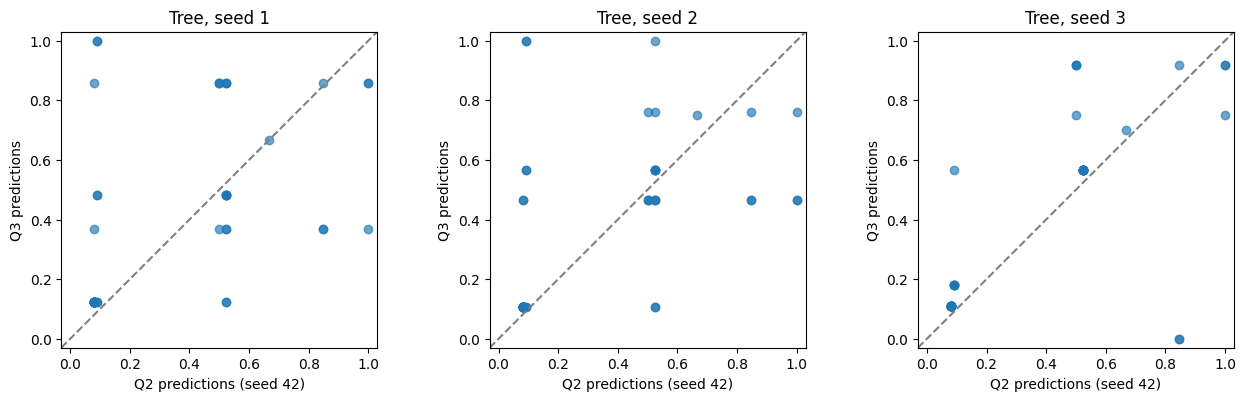

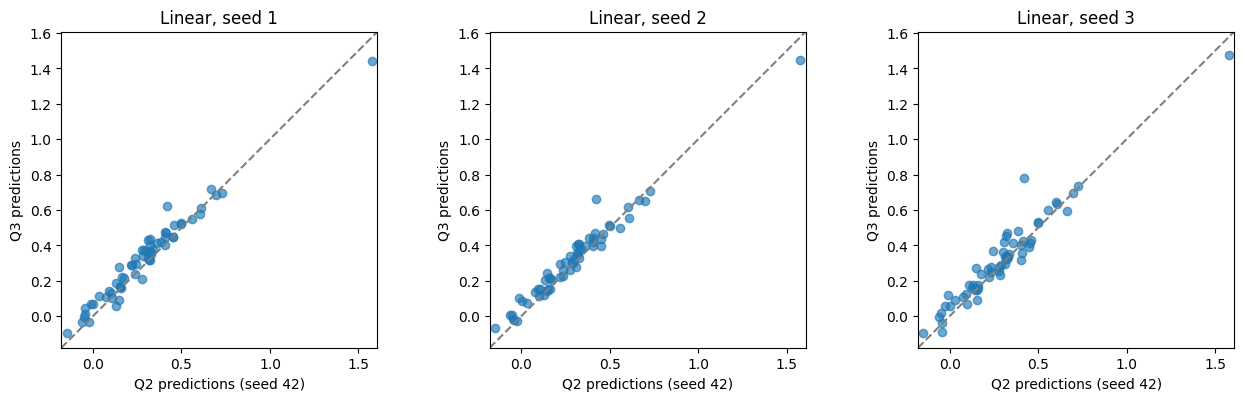

In [55]:
# Make scatterplots of the predicted values on the test set from question 2 against the predicted values 
# for the alternative models from part 3, separately for your trees and linear models.
_, X_test_q2, _, _ = train_test_split(X, y, test_size=0.2, random_state=seed1)

tree_predictions = [
    prediction_tree_seed1,
    tree2.predict_proba(X_test_q2)[:, 1],
    tree3.predict_proba(X_test_q2)[:, 1],
    tree4.predict_proba(X_test_q2)[:, 1]
]

linear_predictions = [
    prediction_linear_seed1,
    linear2.predict(X_test_q2),
    linear3.predict(X_test_q2),
    linear4.predict(X_test_q2)
]

alternative_seeds = [seed2, seed3, seed4]
model_groups = [("Tree", tree_predictions), ("Linear", linear_predictions)]

# Make scatterplots
for model_name, predictions in model_groups:
    q2_predictions = predictions[0]
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))

    low = min(pred.min() for pred in predictions) - 0.03
    high = max(pred.max() for pred in predictions) + 0.03

    for ax, seed, alternative in zip(axes, alternative_seeds, predictions[1:]):
        ax.scatter(q2_predictions, alternative, alpha=0.65)
        ax.plot([low, high], [low, high], "--", color="gray")
        ax.set_xlim(low, high)
        ax.set_ylim(low, high)
        ax.set_aspect("equal")
        ax.set_title(f"{model_name}, seed {seed}")
        ax.set_xlabel(f"Q2 predictions (seed {seed1})")
        ax.set_ylabel("Q3 predictions")

    plt.tight_layout()
    plt.show()

4a: Here, we see that the linear predictions look very similar, since the points fall tightly along the dashed line where the two predictions would be equal. One patient has a predicted value above 1 in all three plots, which is possible because a linear model is not limited to the range 0 to 1. The trees look quite different, since patients in the same leaf get the same predicted probability, which creates vertical stripes of points at the same Q2 value. Within these stripes, the alternative trees often predict very different probabilities, so many points are far from the line. All these comparisons use the same test patients from question 2, some of whom were also in question 3’s training sets (47 to 51 of the 60), so there is some agreement in the plots with those patients.

In [56]:
# Compute the correlation between your model in part 2 and your alternative models in part 3, 
# separately for your trees and linear models.
correlation_results = []

for model_name, predictions in model_groups:
    q2_predictions = predictions[0]

    for seed, alternative in zip(alternative_seeds, predictions[1:]):
        correlation = np.corrcoef(q2_predictions, alternative)[0, 1]

        correlation_results.append({
            "Model": model_name,
            "Q3 seed": seed,
            "Correlation": correlation
        })

display(pd.DataFrame(correlation_results).round(3))

,Model,Q3 seed,Correlation
0,Tree,1,0.567
1,Tree,2,0.583
2,Tree,3,0.767
3,Linear,1,0.980
4,Linear,2,0.982
5,Linear,3,0.963


4b: The linear predictions are highly correlated with the predictions from question 2, with correlations ranging from 0.963 to 0.982. The tree predictions, on the other hand, have much weaker correlations, from 0.567 to 0.767, across the different seeds. The tree predictions tend to move in the same direction, but they have a much less consistent relationship than the linear models do.

In [57]:
# Run a simple linear regression of the predicted values on the test set from the alternative models on the 
# predicted values from question 2, separately for your trees and linear models.

regression_results = []

for model_name, predictions in model_groups:
    # Use Q2 predictions as X and the alternative model's predictions as Y
    q2_predictions = predictions[0].reshape(-1, 1)

    for seed, alternative in zip(alternative_seeds, predictions[1:]):
        comparison = LinearRegression()
        comparison.fit(q2_predictions, alternative)

        regression_results.append({
            "Model": model_name,
            "Q3 seed": seed,
            "Intercept": comparison.intercept_,
            "Slope": comparison.coef_[0],
            "R²": comparison.score(q2_predictions, alternative)
        })

display(pd.DataFrame(regression_results).round(3))

,Model,Q3 seed,Intercept,Slope,R²
0,Tree,1,0.184,0.585,0.322
1,Tree,2,0.169,0.555,0.340
2,Tree,3,0.096,0.775,0.588
3,Linear,1,0.059,0.919,0.961
4,Linear,2,0.059,0.896,0.964
5,Linear,3,0.049,0.929,0.928


4c: For the linear models, we see that the intercepts range from 0.049 to 0.059, staying fairly close to zero, with slopes ranging from 0.896 to 0.929, staying close to one, and R-squared values that range from 0.928 to 0.964, also staying close to one. This is consistent with the points that follow the dashed line in Q4a.

When we look at the trees, the intercepts range from 0.096 to 0.184, being farther from zero than the linear models, with slopes ranging from 0.555 to 0.775, being significantly farther from one. R-squared values range from 0.322 to 0.588, which are much lower than the linear models. Overall, it can be concluded that the linear models give much more similar predictions across the training splits.

### Question 5

*Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?*

Linear models appear to be stable across train/test splits. Their key coefficients like serum creatinine, ejection fraction, and age don’t change much between seeds (diabetes is the main exception, changing sign), and their predictions are very similar, with an average correlation of about 0.98 and the same death/survive prediction for 93% to 95% of patients. The trees, on the other hand, are less stable. They share the same top splits (serum_creatinine, then ejection_fraction), but the cutoffs, the higher-creatinine branch, and the lower splits change from seed to seed, and their predictions agree only moderately, with an average correlation of about 0.64 and the same death/survive prediction for 70% to 88% of patients.

### Question 6

*True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."*

This is true for the linear models in this dataset but not for the trees. The linear models give very similar predictions, with correlations from 0.963 to 0.982, slopes close to 1, and R² between 0.928 and 0.964, but they also do not look substantially different, since their key coefficients stay about the same. The trees do look different from one another, because they all split first on serum_creatinine and ejection_fraction but differ in cutoffs and in the splits below. Those differences are enough to change their predictions, with correlations of only 0.567 to 0.767 and the same death/survive prediction for 70% to 88% of patients. So for the models that look different, the predictions are only moderately similar; “very similar” overstates how closely the trees agree.

### *Reflection on AI assistance
In your own words without generative AI.

For this assignment, AI's main improvement was identifying the need to drop the time variable when building our models, since it confounds with the death/survival target prediction of the patient. This change cascaded through our work and influenced the model metrics, and AI helped us understand what changes we needed to make to the rest of the questions. In terms of limitations, the AI was guessing that some platelet values were set to the mean and therefore should be NaN values. However, there was no way to prove this and so we did not implement this in our code. AI sometimes guesses where information is unknown, but we need to learn from the creators of the dataset before making that kind of chage. There were not many other limitations since the prompts I used provided the AI with appropriate context. We verified each solution against the rubric and even chose to modify one instead of accepting it fully. We do not have remaining concerns about the AI or the assignment.